**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Team 38 · Precision agriculture · Client: John Deere

| | |
|---|---|
| **Goal** | Check how the CPC codes and keywords of Step 0 behave in PATSTAT before using them in Step 1 |
| **Based on** | `tutorial_0/02_step1_general_description.ipynb` (course repository): same client, same year rule, same `PI` filter |
| **Input** | The report *Sector Definition and Patent Query* (Sections 2 and 3): codes, terms, roles and status |
| **PATSTAT environment** | TEST while developing, PROD for the final numbers |

# Step 0 · Checking the query

The course notebook selects a sector as *CPC codes OR keywords*. Our definition is more specific, because some codes and terms only count together with others (report, Sections 2.1 and 3.1):

**sector = [stand-alone codes OR sector terms OR ((technology codes OR technology terms) AND (context codes OR context terms))] AND NOT exclusions**

Exclusions (role `X`): lawn mowers, as in the WIPO query for planting and harvesting. Before matching, compounds such as *wind farm* or *fish farm* are removed from the text, so that *farm\** only counts agricultural farms.

This notebook answers these questions:

1. How many families does each code and each term retrieve, alone and inside the sector?
2. How large is each block of the query, and how much does it add?
3. How many families would be lost if a single code or term were removed (its unique contribution)?
4. What do the retrieved patents look like? Sample titles for each code and term, in particular those marked *to validate*.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from epo.tipdata.patstat import PatstatClient

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_rows", 200)

## 2. Configuration

Codes and terms are copied from the report. `role` decides how an item is combined (Section 2.1 of the report); `status` is `selected` or `to_validate`.

**Codes.** A family matches a code if any of its CPC symbols, with blanks removed, starts with the prefix. Prefixes end with `/` where needed, so that `A01M7/` does not also match `A01M75/...`.

**Terms.** Each term is a regular expression (BigQuery `REGEXP_CONTAINS`) searched in the lower-case title and abstract of every application of the family. `\b` marks a word boundary, so `\bgis\b` does not match *logistics*; `[- ]?` accepts variants with and without hyphen or space.

In [2]:
# ---------------------------------------------------------------- environment
ENV = "PROD"                       # develop on TEST, switch to "PROD" for the final numbers
OUTPUT_DIR = Path("outputs/step0")
YEAR_MIN, YEAR_MAX = 2000, 2022    # family year = earliest priority year (PW rule, as in notebook 02)
IPR_TYPE = "PI"                    # patents of invention only
SEED = 38                          # for reproducible samples
SAMPLE_PER_ITEM = 8                # sample titles shown for each code or term

# ---------------------------------------------------------------- CPC codes (report, Section 2.2)
# name: (prefix, role, status)    role: S = stand-alone, T = technology, A = context, X = exclusion
CODES = {
    "A01B79/005":     ("A01B79/005",     "S", "selected"),
    "A01B69/001-004-008": (("A01B69/001", "A01B69/004", "A01B69/008"), "S", "selected"),
    "A01D41/1271-72": (("A01D41/1271", "A01D41/1272"), "S", "selected"),
    "A01D41/1278":    ("A01D41/1278",    "S", "selected"),
    "G05D1/43":       ("G05D1/43",       "T", "selected"),
    "G01S19":         ("G01S19/",        "T", "selected"),
    "B64U":           ("B64U",           "T", "selected"),
    "G06T2207/10032": ("G06T2207/10032", "T", "selected"),
    "G06T2207/30188": ("G06T2207/30188", "T", "selected"),
    "G06V20/188":     ("G06V20/188",     "T", "selected"),
    "G06Q50/02":      ("G06Q50/02",      "A", "selected"),
    "A01B":           ("A01B",           "A", "selected"),
    "A01C":           ("A01C",           "A", "selected"),
    "A01D":           ("A01D",           "A", "selected"),
    "A01G25":         ("A01G25/",        "A", "selected"),
    "A01M7":          ("A01M7/",         "A", "selected"),
    "A01D2101 lawn-mowers": ("A01D2101/",   "X", "selected"),   # exclusion, as WIPO [8, p. 98]
}

# ---------------------------------------------------------------- keywords (report, Sections 3.2-3.4)
# name: (regex, role, status)     role: K1 = sector term, K2 = technology term, AG = context term, X = exclusion
TERMS = {
    # sector terms
    "precision agriculture":         (r"precision[- ]agricultur",                 "K1", "selected"),
    "precision farming":             (r"precision[- ]farming",                    "K1", "selected"),
    "site-specific crop management": (r"site[- ]specific crop management",        "K1", "selected"),
    "satellite farming/agriculture": (r"satellite (farming|agricultur)",          "K1", "to_validate"),
    "site-specific farming":         (r"site[- ]specific farming",                "K1", "to_validate"),
    "soil-specific crop management": (r"soil[- ]specific crop management",        "K1", "to_validate"),
    "prescription farming":          (r"prescription farming",                    "K1", "to_validate"),
    "spatially prescriptive farming":(r"spatially prescriptive farming",          "K1", "to_validate"),
    "spatially variable field op.":  (r"spatially variable field operation",      "K1", "to_validate"),
    # technology terms
    "variable rate / VRT":           (r"variable[- ]rate|\bvrt\b",                "K2", "selected"),
    "yield monitor/map":             (r"yield (monitor|map)",                     "K2", "selected"),
    "soil map":                      (r"soil map",                                "K2", "selected"),
    "management zone":               (r"management zone",                         "K2", "selected"),
    "prescription map":              (r"prescription map",                        "K2", "to_validate"),
    "section control":               (r"(automated|automatic) section control",   "K2", "to_validate"),
    "guidance system":               (r"guidance system|automated guidance|auto[- ]?guidance", "K2", "selected"),
    "auto-steer":                    (r"auto[- ]?steer|automatic steering",       "K2", "selected"),
    "controlled traffic/tramlines":  (r"controlled traffic farming|tramline",     "K2", "to_validate"),
    "GPS":                           (r"\bgps\b|global positioning system",       "K2", "selected"),
    "GNSS":                          (r"\bgnss\b|global navigation satellite",    "K2", "selected"),
    "GIS":                           (r"\bgis\b|geographic information system",   "K2", "selected"),
    "remote sensing":                (r"remote[- ]sensing",                       "K2", "selected"),
    "drone / UAV":                   (r"\bdrones?\b|\buavs?\b|unmanned aerial vehicle", "K2", "selected"),
    "aerial/satellite imagery":      (r"(aerial|satellite) imagery",              "K2", "selected"),
    "weed mapping":                  (r"weed map",                                "K2", "to_validate"),
    "soil sensor":                   (r"soil sensor|in[- ]ground sensor",         "K2", "selected"),
    "targeted/spot/precision spray": (r"targeted spray|spot[- ]?spray|precision spray", "K2", "selected"),
    # agricultural context terms
    "agricultur*":                   (r"\bagricultur",                            "AG", "selected"),
    "farm*":                         (r"\bfarm",                                  "AG", "selected"),
    "cultivat*":                     (r"\bcultivat",                              "AG", "selected"),
    "crop(s)":                       (r"\bcrops?\b",                              "AG", "to_validate"),
    "lawn":                          (r"\blawn",                                  "X", "selected"),   # exclusion
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
patstat = PatstatClient(env=ENV)


def run_sql(sql):
    """Run a standard-SQL query; on error, print BigQuery's own message instead of the long traceback."""
    try:
        return pd.DataFrame(patstat.sql_query(sql, use_legacy_sql=False))
    except Exception as e:
        msg = getattr(e, "message", None) or str(e)
        raise RuntimeError(f"BigQuery error: {msg[:1500]}") from None

print(f"env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} | {len(CODES)} code entries | {len(TERMS)} term entries")

env: PROD | years 2000-2022 | 17 code entries | 32 term entries


## 3. One row per family, one flag per code and term

The query below is built from the configuration. It runs entirely in BigQuery and creates, for every family in the time window, one TRUE/FALSE column per code and per term, plus the four blocks of the definition:

| Column | Meaning |
|---|---|
| `standalone` | any S code or any K1 term |
| `technology` | any T code or any K2 term |
| `context` | any A (context) code or any AG term |
| `excluded` | any X code or X term |
| `sector` | `(standalone OR (technology AND context)) AND NOT excluded` |

In [3]:
def col(name, kind):
    """Safe SQL column name for a code (c_) or a term (k_)."""
    clean = "".join(ch if ch.isalnum() else "_" for ch in name.lower())
    return f"{kind}_{clean}".strip("_")


CODE_COL = {name: col(name, "c") for name in CODES}
TERM_COL = {name: col(name, "k") for name in TERMS}
ITEMS = pd.DataFrame(
    [(n, CODE_COL[n], "code", r, s) for n, (_, r, s) in CODES.items()]
    + [(n, TERM_COL[n], "term", r, s) for n, (_, r, s) in TERMS.items()],
    columns=["item", "column", "type", "role", "status"],
)


def code_expr(prefix):
    prefixes = prefix if isinstance(prefix, tuple) else (prefix,)
    return " OR ".join(f"STARTS_WITH(sym, '{p}')" for p in prefixes)


def any_of(role):
    cols = ITEMS.loc[ITEMS["role"] == role, "column"]
    return "(" + " OR ".join(cols) + ")"


kw_flags = ",\n    ".join(
    f"LOGICAL_OR(REGEXP_CONTAINS(doc_text, r'{rx}')) AS {TERM_COL[n]}" for n, (rx, _, _) in TERMS.items()
)
cpc_flags = ",\n    ".join(
    f"LOGICAL_OR({code_expr(p)}) AS {CODE_COL[n]}" for n, (p, _, _) in CODES.items()
)
all_flags = ",\n    ".join(f"IFNULL({c}, FALSE) AS {c}" for c in ITEMS["column"])

FLAGS_SQL = f"""
WITH fam AS (
  SELECT docdb_family_id AS fam_id, MIN(earliest_filing_year) AS year
  FROM tls201_appln
  WHERE ipr_type = '{IPR_TYPE}'
  GROUP BY docdb_family_id
  HAVING MIN(earliest_filing_year) BETWEEN {YEAR_MIN} AND {YEAR_MAX}
),
texts AS (
  SELECT a.docdb_family_id AS fam_id,
         REGEXP_REPLACE(LOWER(CONCAT(IFNULL(t.appln_title, ''), ' ', IFNULL(b.appln_abstract, ''))),
                        r'\\b(wind|solar|fish|server|data|wave|tidal|energy|photovoltaic|pv|offshore)( power)?[- ]?farm\\w*', ' ') AS doc_text
  FROM tls201_appln a
  LEFT JOIN tls202_appln_title t ON t.appln_id = a.appln_id
  LEFT JOIN tls203_appln_abstr b ON b.appln_id = a.appln_id
  WHERE a.ipr_type = '{IPR_TYPE}'
),
kw AS (
  SELECT fam_id,
    {kw_flags}
  FROM texts
  GROUP BY fam_id
),
cpc AS (
  SELECT a.docdb_family_id AS fam_id,
    {cpc_flags}
  FROM tls201_appln a
  JOIN (SELECT appln_id, REPLACE(cpc_class_symbol, ' ', '') AS sym FROM tls224_appln_cpc) c
    ON c.appln_id = a.appln_id
  WHERE a.ipr_type = '{IPR_TYPE}'
  GROUP BY fam_id
),
flags AS (
  SELECT fam.fam_id, fam.year,
    {all_flags}
  FROM fam
  LEFT JOIN kw  ON kw.fam_id  = fam.fam_id
  LEFT JOIN cpc ON cpc.fam_id = fam.fam_id
),
blocks AS (
  SELECT *,
    ({any_of("S")} OR {any_of("K1")}) AS standalone,
    ({any_of("T")} OR {any_of("K2")}) AS technology,
    ({any_of("A")} OR {any_of("AG")}) AS context,
    {any_of("X")} AS excluded
  FROM flags
)
SELECT *, ((standalone OR (technology AND context)) AND NOT excluded) AS sector
FROM blocks
"""

print(FLAGS_SQL[:1500], "\n...")


WITH fam AS (
  SELECT docdb_family_id AS fam_id, MIN(earliest_filing_year) AS year
  FROM tls201_appln
  WHERE ipr_type = 'PI'
  GROUP BY docdb_family_id
  HAVING MIN(earliest_filing_year) BETWEEN 2000 AND 2022
),
texts AS (
  SELECT a.docdb_family_id AS fam_id,
         REGEXP_REPLACE(LOWER(CONCAT(IFNULL(t.appln_title, ''), ' ', IFNULL(b.appln_abstract, ''))),
                        r'\b(wind|solar|fish|server|data|wave|tidal|energy|photovoltaic|pv|offshore)( power)?[- ]?farm\w*', ' ') AS doc_text
  FROM tls201_appln a
  LEFT JOIN tls202_appln_title t ON t.appln_id = a.appln_id
  LEFT JOIN tls203_appln_abstr b ON b.appln_id = a.appln_id
  WHERE a.ipr_type = 'PI'
),
kw AS (
  SELECT fam_id,
    LOGICAL_OR(REGEXP_CONTAINS(doc_text, r'precision[- ]agricultur')) AS k_precision_agriculture,
    LOGICAL_OR(REGEXP_CONTAINS(doc_text, r'precision[- ]farming')) AS k_precision_farming,
    LOGICAL_OR(REGEXP_CONTAINS(doc_text, r'site[- ]specific crop management')) AS k_site_specific_crop_manag

## 4. How many families does each item retrieve?

`all_families`: families that carry the code or contain the term, whatever else they contain.
`in_sector`: of those, the families that enter the sector under our rule. For an operation code such as A01B, the gap between the two numbers shows how many soil-working patents are left out because they use no precision technology.

counts_sql = "SELECT COUNT(*) AS families_in_window,\n  COUNTIF(sector) AS sector,\n  " + ",\n  ".join(
    f"COUNTIF({c}) AS {c}__all, COUNTIF({c} AND sector) AS {c}__in" for c in ITEMS["column"]
) + f"\nFROM ({FLAGS_SQL})"

totals = run_sql(counts_sql).iloc[0]
print(f"Families {YEAR_MIN}-{YEAR_MAX} in {ENV}: {int(totals['families_in_window']):,}")
print(f"Families in the sector: {int(totals['sector']):,}")

item_counts = ITEMS.assign(
    all_families=[int(totals[f"{c}__all"]) for c in ITEMS["column"]],
    in_sector=[int(totals[f"{c}__in"]) for c in ITEMS["column"]],
)
item_counts

## 5. Download the sector families

Only the families in the sector are downloaded, with their flags. All the following tables are computed in pandas from this download.

In [5]:
sector = run_sql(f"SELECT * FROM ({FLAGS_SQL}) WHERE sector")
flag_cols = list(ITEMS["column"])
bool_cols = flag_cols + ["standalone", "technology", "context", "excluded", "sector"]
sector[bool_cols] = sector[bool_cols].astype(bool)
print(f"{len(sector):,} sector families downloaded")
sector.to_csv(OUTPUT_DIR / f"sector_flags_{ENV}.csv", index=False)

14,377 sector families downloaded


## 6. Size of each block

How the sector is built: families reached by the stand-alone block, by the combined block (technology AND context), and by both.

In [6]:
combined = sector["technology"] & sector["context"]
blocks = pd.Series({
    "stand-alone block (S codes or K1 terms)": int(sector["standalone"].sum()),
    "  of which only S codes": int((sector[ITEMS.query("role == 'S'")["column"]].any(axis=1)
                                     & ~sector[ITEMS.query("role == 'K1'")["column"]].any(axis=1)).sum()),
    "  of which only K1 terms": int((~sector[ITEMS.query("role == 'S'")["column"]].any(axis=1)
                                      & sector[ITEMS.query("role == 'K1'")["column"]].any(axis=1)).sum()),
    "combined block (technology AND context)": int(combined.sum()),
    "both blocks": int((sector["standalone"] & combined).sum()),
    "only combined block": int((~sector["standalone"] & combined).sum()),
    "sector (total)": len(sector),
}, name="families")
blocks.to_frame()

,families
stand-alone block (S codes or K1 terms),4842
of which only S codes,4433
of which only K1 terms,344
combined block (technology AND context),10785
both blocks,1250
only combined block,9535
sector (total),14377


## 7. Unique contribution of each code and term

For each item we remove it from the query and recompute the sector. `unique` is the number of families that would be lost: they are in the sector only because of that item. An item with a large `unique` value drives the size of the sector, so its precision matters most in the validation.

In [7]:
def recompute(df, drop_col):
    f = df[flag_cols].copy()
    f[drop_col] = False
    any_ = lambda role: f[ITEMS.loc[ITEMS["role"] == role, "column"]].any(axis=1)
    return ((any_("S") | any_("K1")) | ((any_("T") | any_("K2")) & (any_("A") | any_("AG")))) & ~any_("X")


unique = {c: int((~recompute(sector, c)).sum()) for c in flag_cols}
contrib = item_counts.assign(
    unique=item_counts["column"].map(unique),
    unique_share=lambda d: (d["unique"] / len(sector) * 100).round(1),
)[["item", "type", "role", "status", "all_families", "in_sector", "unique", "unique_share"]]
contrib.to_csv(OUTPUT_DIR / f"item_contribution_{ENV}.csv", index=False)
contrib.sort_values("unique", ascending=False)

,item,type,role,status,all_families,in_sector,unique,unique_share
39,drone / UAV,term,K2,selected,71194,3958,2077,14.4
44,agricultur*,term,AG,selected,161674,6049,1607,11.2
0,A01B79/005,code,S,selected,2277,2260,1253,8.7
1,A01B69/001-004-008,code,S,selected,2236,2175,1123,7.8
15,A01M7,code,A,selected,13164,2263,1013,7.0
47,crop(s),term,AG,to_validate,99646,3787,1003,7.0
38,remote sensing,term,K2,selected,19858,1689,941,6.5
35,GPS,term,K2,selected,70220,1392,813,5.7
10,G06Q50/02,code,A,selected,19389,2277,762,5.3
45,farm*,term,AG,selected,125503,2083,630,4.4


## 8. What do the retrieved patents look like?

For each code and term, a random sample of sector families that contain it (seed fixed in the configuration), with one title per family (English if available). Read the titles of the items marked `to_validate` first: if most of them are not precision agriculture, the item is a candidate for removal in the validation.

In [ ]:
rng = np.random.default_rng(SEED)
samples = []
for _, row in ITEMS.iterrows():
    hits = sector.loc[sector[row["column"]], "fam_id"].to_numpy()
    if len(hits) == 0:
        continue
    pick = rng.choice(hits, size=min(SAMPLE_PER_ITEM, len(hits)), replace=False)
    samples += [(row["item"], row["role"], row["status"], int(f)) for f in pick]
samples = pd.DataFrame(samples, columns=["item", "role", "status", "fam_id"])

ids = ", ".join(str(i) for i in samples["fam_id"].unique())
titles = run_sql(f"""
SELECT a.docdb_family_id AS fam_id,
       ARRAY_AGG(t.appln_title ORDER BY IF(t.appln_title_lg = 'en', 0, 1), a.appln_id LIMIT 1)[OFFSET(0)] AS title
FROM tls201_appln a
JOIN tls202_appln_title t ON t.appln_id = a.appln_id
WHERE a.docdb_family_id IN ({ids})
GROUP BY a.docdb_family_id
""")

samples = samples.merge(titles, on="fam_id", how="left")
samples.to_csv(OUTPUT_DIR / f"sample_titles_{ENV}.csv", index=False)
print(f"{len(samples)} sample rows saved")

In [ ]:
# Items to validate first
samples.query("status == 'to_validate'")[["item", "fam_id", "title"]]

In [ ]:
# All the other items
samples.query("status == 'selected'")[["item", "fam_id", "title"]]

## 9. Notes

- **TEST vs PROD.** TEST is a reduced copy of PATSTAT: absolute numbers are not meaningful, the shares and the sample titles are. Switch `ENV = "PROD"` for the final numbers.
- **Language.** Terms are in English. Titles and abstracts in other languages are found only through the CPC codes.
- **Subgroups.** A code includes the symbols that start with its prefix. For most codes this equals the CPC subgroups; the CPC hierarchy is not always reflected in the digits, so the PROD run should be checked against the scheme.
- **Next step.** Hand-label a random sample of sector families (report, Section 4) and decide on the items marked `to_validate`.

## 10. Look at A01B79/005 excluded patents

In [8]:
excluded_pa = run_sql(f"""
SELECT
    fam_id,
    {CODE_COL["A01D2101 lawn-mowers"]} AS excluded_by_cpc,
    {TERM_COL["lawn"]} AS excluded_by_lawn
FROM ({FLAGS_SQL})
WHERE {CODE_COL["A01B79/005"]}
  AND excluded
ORDER BY fam_id
""")

print("Families to inspect:", len(excluded_pa))
display(excluded_pa)

if not excluded_pa.empty:
    family_ids_sql = ", ".join(
        str(int(fid)) for fid in excluded_pa["fam_id"]
    )

    excluded_documents = run_sql(f"""
    SELECT
        a.docdb_family_id AS fam_id,
        a.appln_id,
        a.appln_auth,
        a.appln_nr,
        t.appln_title_lg AS title_language,
        t.appln_title AS title,
        b.appln_abstract_lg AS abstract_language,
        b.appln_abstract AS abstract
    FROM tls201_appln a
    LEFT JOIN tls202_appln_title t
        ON t.appln_id = a.appln_id
    LEFT JOIN tls203_appln_abstr b
        ON b.appln_id = a.appln_id
    WHERE a.docdb_family_id IN ({family_ids_sql})
      AND a.ipr_type = '{IPR_TYPE}'
    ORDER BY a.docdb_family_id, a.appln_id
    """)
else:
    excluded_documents = pd.DataFrame()

Families to inspect: 17


,fam_id,excluded_by_cpc,excluded_by_lawn
0,9933736,False,True
1,51263517,True,False
2,51418248,False,True
3,56008534,True,False
4,58672739,True,False
5,59054002,True,True
6,60294057,True,False
7,62976858,True,False
8,64819849,True,False
9,66349389,True,False


In [19]:
def show_excluded_family(position=0):
    if excluded_pa.empty:
        print("No excluded families to inspect.")
        return

    if not 0 <= position < len(excluded_pa):
        print(f"Choose a position from 0 to {len(excluded_pa) - 1}.")
        return

    family = excluded_pa.iloc[position]
    family_id = int(family["fam_id"])

    print("FAMILY:", family_id)
    print("Excluded by CPC:", family["excluded_by_cpc"])
    print("Excluded by 'lawn':", family["excluded_by_lawn"])

    documents = excluded_documents.loc[
        excluded_documents["fam_id"] == family_id
    ]

    for _, row in documents.iterrows():
        print("\nAPPLICATION ID:", row["appln_id"])
        print("OFFICE / NUMBER:", row["appln_auth"], row["appln_nr"])
        print("TITLE:", row["title"])
        print("ABSTRACT LANGUAGE:", row["abstract_language"])
        print("ABSTRACT:", row["abstract"])
        print("-" * 80)


show_excluded_family(position=10)

FAMILY: 68165878
Excluded by CPC: True
Excluded by 'lawn': False

APPLICATION ID: 520226061
OFFICE / NUMBER: WO 2019053163
TITLE: LOCALIZED DATA MAPPING FOR INDOOR AND OUTDOOR APPLICATIONS
ABSTRACT LANGUAGE: en
ABSTRACT: A method for generating a localized data map, the method including (a) traversing an area with a machine, the machine including at least one sensor, wherein the sensor is configured to receive data; (b) collecting data of the area utilizing the sensor; and (c) communicating the data to generate a localized data map. A system and method for generating a localized turf grass data map, the method including (a) traversing an area of turf grass with an outdoor power equipment machine, the outdoor power equipment machine including at least one sensor, wherein the sensor is configured to receive data; (b) collecting turf grass data utilizing the sensor; and (c) communicating the turf grass data to generate a localized turf grass data map.
-------------------------------------

## 11. SBERT - UMAP

In [20]:
if sector.empty:
    raise ValueError("The sector dataset is empty.")

family_ids_sql = ", ".join(
    str(int(fid)) for fid in sorted(sector["fam_id"].unique())
)

sbert_data = run_sql(f"""
SELECT
    a.docdb_family_id AS fam_id,
    a.appln_id,
    b.appln_abstract AS abstract
FROM tls201_appln a
JOIN tls203_appln_abstr b
    ON b.appln_id = a.appln_id
WHERE a.docdb_family_id IN ({family_ids_sql})
  AND a.ipr_type = '{IPR_TYPE}'
  AND LOWER(TRIM(b.appln_abstract_lg)) = 'en'
  AND LENGTH(TRIM(b.appln_abstract)) > 0
QUALIFY ROW_NUMBER() OVER (
    PARTITION BY a.docdb_family_id
    ORDER BY
        a.appln_filing_date,
        a.appln_id,
        b.appln_abstract
) = 1
ORDER BY fam_id
""")

print("Selected families:", sector["fam_id"].nunique())
print("Families with an English abstract:", len(sbert_data))
print(
    "Families not scored:",
    sector["fam_id"].nunique() - len(sbert_data),
)

if sbert_data.empty:
    raise ValueError("No English abstracts available for SBERT.")

Selected families: 14377
Families with an English abstract: 13911
Families not scored: 466


In [21]:
%pip install -q sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [22]:
from sentence_transformers import SentenceTransformer

SBERT_MODEL = "graziasveva93/sbert-adapt-ub"

PA_DESCRIPTION = """
Systems, devices and methods for precision agriculture in crop production,
measuring spatial or temporal variation in soil and crop conditions and
supporting site-specific management and targeted agricultural operations.
Inventions may address one or more functions: soil and crop sensing,
remote sensing, yield monitoring and mapping, geospatial data processing,
georeferenced field mapping and prescription maps, GNSS-based guidance
or automatic steering of agricultural machinery, variable-rate application
of seed, fertilizer, irrigation water or crop protection products, and
selective detection and treatment of individual plants or weeds.
""".strip()

model = SentenceTransformer(SBERT_MODEL)

print("Model:", SBERT_MODEL)
print("Maximum input length:", model.max_seq_length, "tokens")

# Keep embeddings aligned with the original order of sbert_data.
abstract_embeddings = model.encode(
    sbert_data["abstract"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

description_embedding = model.encode(
    PA_DESCRIPTION,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

# Dot product equals cosine similarity for normalised embeddings.
sbert_data["cosine_similarity"] = (
    abstract_embeddings @ description_embedding
)

sbert_ranked = (
    sbert_data
    .sort_values(
        ["cosine_similarity", "fam_id"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

sbert_ranked[["fam_id", "appln_id", "cosine_similarity"]].head(10)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model: graziasveva93/sbert-adapt-ub
Maximum input length: 512 tokens


Batches:   0%|          | 0/435 [00:00<?, ?it/s]

,fam_id,appln_id,cosine_similarity
0,77687570,557481717,0.972885
1,62136448,494551828,0.969477
2,72266830,546027583,0.965883
3,72921896,539936080,0.963870
4,26928597,54348234,0.963744
5,80654579,568778288,0.963137
6,50002980,414711246,0.962094
7,86761396,594353741,0.961508
8,76046311,551316585,0.961483
9,88268670,600068990,0.961127


In [23]:
bands = pd.cut(
    sbert_data["cosine_similarity"],
    bins=[-np.inf, 0, 0.2, 0.4, 0.6, 0.8, np.inf],
    labels=[
        "< 0",
        "0–<0.2",
        "0.2–<0.4",
        "0.4–<0.6",
        "0.6–<0.8",
        "≥ 0.8",
    ],
    right=False,
)

similarity_counts = (
    bands.value_counts(sort=False)
    .rename_axis("cosine_similarity")
    .reset_index(name="n_families")
)

similarity_counts["share_pct"] = (
    100 * similarity_counts["n_families"] / len(sbert_data)
).round(1)

print("Total families scored:", len(sbert_data))
similarity_counts

Total families scored: 13911


,cosine_similarity,n_families,share_pct
0,< 0,83,0.6
1,0–<0.2,337,2.4
2,0.2–<0.4,1138,8.2
3,0.4–<0.6,3005,21.6
4,0.6–<0.8,4673,33.6
5,≥ 0.8,4675,33.6


In [24]:
%pip install -q umap-learn

Note: you may need to restart the kernel to use updated packages.


/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


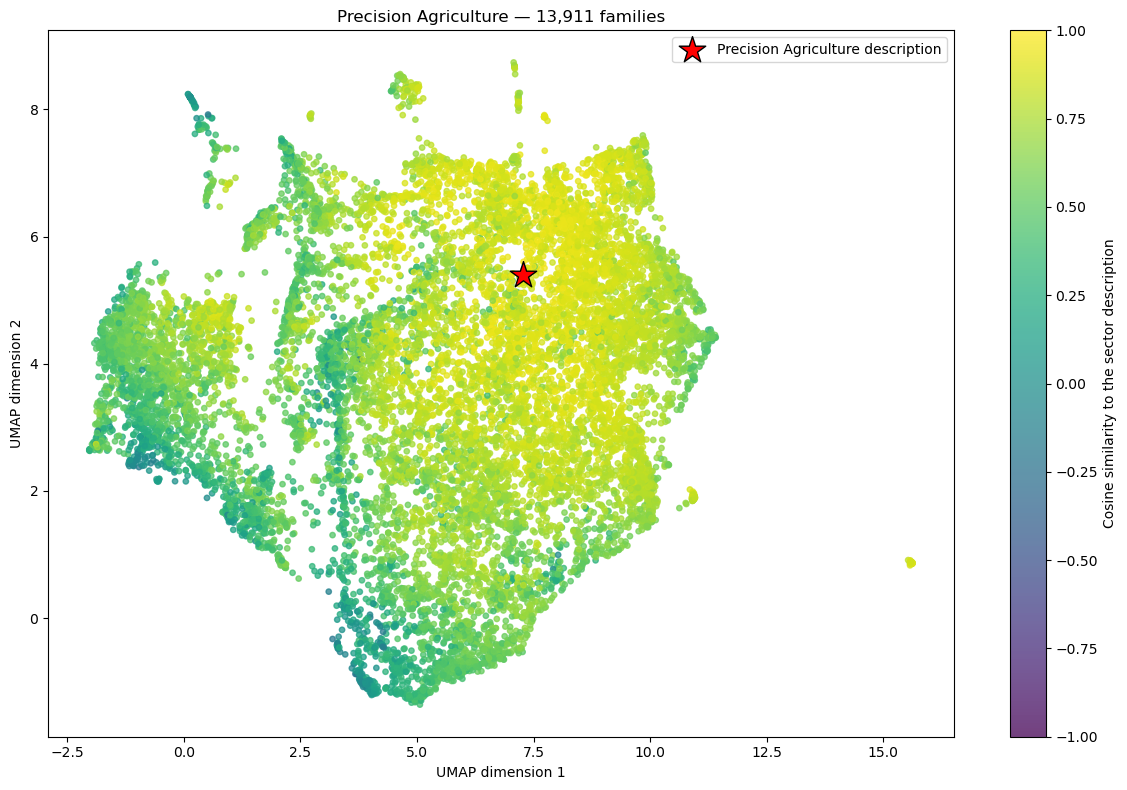

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import umap

# Use the same row order used to generate the embeddings.
# Do not replace sbert_data with the sorted sbert_ranked.
umap_data = sbert_data.copy()

assert len(umap_data) == len(abstract_embeddings), (
    "Rerun the SBERT cells: rows and embeddings do not match."
)

# Include the sector description in the same projection.
umap_input = np.vstack([
    abstract_embeddings,
    description_embedding.reshape(1, -1),
])

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)

coords = reducer.fit_transform(umap_input)

umap_data[["UMAP_1", "UMAP_2"]] = coords[:-1]
pa_xy = coords[-1]

# Plot families coloured by their original cosine similarity.
fig, ax = plt.subplots(figsize=(12, 8))

points = ax.scatter(
    umap_data["UMAP_1"],
    umap_data["UMAP_2"],
    c=umap_data["cosine_similarity"],
    cmap="viridis",
    vmin=-1,
    vmax=1,
    s=15,
    alpha=0.75,
)

ax.scatter(
    pa_xy[0],
    pa_xy[1],
    marker="*",
    s=400,
    color="red",
    edgecolors="black",
    label="Precision Agriculture description",
    zorder=5,
)

fig.colorbar(
    points,
    ax=ax,
    label="Cosine similarity to the sector description",
)

ax.set(
    xlabel="UMAP dimension 1",
    ylabel="UMAP dimension 2",
    title=f"Precision Agriculture — {len(umap_data):,} families",
)

ax.legend()
plt.tight_layout()
plt.show()